In [4]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Jinan121005")

In [6]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
"MERGE (a:Person {name: $name}) "
"MERGE (friend:Person {name: $friend_name}) "
"MERGE (a)-[:KNOWS]->(friend)",
name=name, friend_name=friend_name, database_="neo4j",
)

In [7]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


1. Apa nama database yang digunakan pada tutorial ini?
neo4j, yaitu database default bawaan Neo4j.

2. Sebutkan akses lain yang dapat digunakan untuk mengakses database lain dalam 1 instance!
Lewat driver Python dengan mengganti parameternya, misalnya database_="namadb" pada execute_query, atau driver.session(database="namadb").
Untuk mengelola database (DDL), perintah dijalankan di database system: SHOW DATABASES, CREATE DATABASE namadb, DROP DATABASE namadb.

3. Apa jenis graf pertemanan yang telah dibuat di sini?
Graf berarah (directed graph), karena relasi KNOWS -> (friend) punya arah dari Arthur ke temannya. Arthur mengenal Guinevere, Lancelot, dan Merlin, tapi belum tentu sebaliknya. Grafnya juga tidak berbobot karena relasi KNOWS tidak punya properti, dan semua simpulnya berlabel Person. Hasilnya 4 simpul dan 3 relasi.

# 1.3 Impor Data RetailRocket ke Neo4j

In [8]:
import pandas as pd

df = pd.read_csv("data/events.csv")
print(df.shape)
print(df["event"].value_counts())
df.head()

(2756101, 5)
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [10]:
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "Jinan121005"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="neo4j")

In [15]:
import os, sys
import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase

class Args:
    user = "neo4j"
    password = "Jinan121005"
    bolt = "neo4j://127.0.0.1:7687"
    source = "data"

args = Args()

In [16]:
csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

In [17]:
try:
    driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
    driver.verify_connectivity()
    print("Koneksi berhasil")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Koneksi berhasil


In [23]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")


In [26]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

impor penuh events.csv (2,76 juta baris) tidak dijalankan di notebook ini, karena isi database akan dikosongkan lagi pada tahap 2.1.
Mekanisme yang sama (create_constraints + import_batch, batch 5.000 baris) dipakai pada sel Upload data P1 di bawah, tetapi hanya untuk data periode P1.

In [ ]:
batch_size = 5000

with driver.session() as session:
    create_constraints(session)
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    total_rows = len(pd.read_csv(csv_file_path))
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

DriverError: Driver closed

# Soal

## 2.1 Wrangling dan EDA

In [28]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df["dt"].min(), df["dt"].max())

2015-05-03 03:00:04.384000 2015-09-18 02:59:47.788000


### Filter timestamp (P1 = 14 Juni - 27 Juni P2 = 28 Juni - 4 Jul) dan simpan .csv

In [29]:
P1_START, P1_END = "2015-06-14", "2015-06-28"   # sampai 27 Juni
P2_START, P2_END = "2015-06-28", "2015-07-05"   # sampai 4 Juli

P1 = df[(df.dt >= P1_START) & (df.dt < P1_END)].drop(columns="dt")
P2 = df[(df.dt >= P2_START) & (df.dt < P2_END)].drop(columns="dt")

P1.to_csv("data/events_p1.csv", index=False)
P2.to_csv("data/events_p2.csv", index=False)
print("P1:", len(P1), "baris | P2:", len(P2), "baris")
print(P1["event"].value_counts())

P1: 284624 baris | P2: 140678 baris
event
view           274497
addtocart        7570
transaction      2557
Name: count, dtype: int64


Kosongkan database di Neo4j Query:
MATCH (n) DETACH DELETE n;

Database dikosongkan sebelum impor agar graf hanya berisi data P1 (14-27 Juni 2015), sehingga hasil komposisi subgraph, VSM, dan similarity tidak tercampur dengan data sisa dari tutorial atau percobaan impor sebelumnya

### Upload data P1 (training)

In [30]:
csv_file_path = "data/events_p1.csv"
driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))

batch_size = 5000
with driver.session(database="neo4j") as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    total_rows = sum(1 for _ in open(csv_file_path, encoding="utf-8")) - 1
    total_chunks = (total_rows // batch_size) + 1

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        session.execute_write(import_batch, chunk.to_dict(orient="records"))

driver.close()
print("Proses impor berhasil.")

Mengimpor Batch Data:   0%|          | 0/57 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=7, column=5, offset=139>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 139, 'line': 7, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\

Proses impor berhasil.


### Komposisi subgraph

In [31]:
with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as d:
    with d.session(database="neo4j") as s:
        nodes = s.run("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah").data()
        rels  = s.run("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah").data()

display(pd.DataFrame(nodes))
display(pd.DataFrame(rels))

,jenis_simpul,jumlah
0,Visitor,147816
1,Item,76702


,jenis_relasi,jumlah
0,VIEWED,274497
1,ADDED_TO_CART,7570
2,BOUGHT,2557


*Penjelasan Cypher yang digunakan*

| Query | Penjelasan |
|---|---|
| `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah` | `MATCH (n)` mengambil semua simpul. `labels(n)[0]` adalah label pertama simpul (di graf ini tiap simpul punya tepat satu label: `Visitor` atau `Item`). `count(n)` adalah fungsi agregasi, dan kolom non-agregat (`jenis_simpul`) otomatis menjadi kunci pengelompokan, sehingga hasilnya jumlah simpul per label. |
| `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah` | Pola `()-[r]->()` mengambil semua relasi berarah tanpa memfilter simpul ujungnya. `type(r)` memberi nama tipe relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`), lalu `count(r)` menghitung jumlahnya per tipe. |

Di Python API, session.run(query).data() mengembalikan list of dict yang langsung diubah menjadi DataFrame.

*Hasil (data P1):* 147.816 simpul Visitor + 76.702 simpul Item = 224.518 simpul. Relasi: 274.497 VIEWED + 7.570 ADDED_TO_CART + 2.557 BOUGHT = 284.624 relasi, sama dengan jumlah baris events_p1.csv (satu baris event menjadi satu relasi).

### VSM User dan Item

In [32]:
from scipy.sparse import csr_matrix
import numpy as np

q = "MATCH (v:Visitor)-[r]->(i:Item) RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t"
with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as d:
    with d.session(database="neo4j") as s:
        inter = pd.DataFrame(s.run(q).data())

bobot = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
inter["w"] = inter["t"].map(bobot)
inter = inter.groupby(["u", "i"], as_index=False)["w"].max()

u_idx = {u: k for k, u in enumerate(inter["u"].unique())}
i_idx = {i: k for k, i in enumerate(inter["i"].unique())}

M = csr_matrix(
    (inter["w"], (inter["u"].map(u_idx), inter["i"].map(i_idx))),
    shape=(len(u_idx), len(i_idx)),
)

1. User

In [33]:
print("Shape VSM User :", M.shape)
print("Jumlah vektor  :", M.shape[0], "| Dimensi vektor:", M.shape[1])
print("Non-zero       :", M.nnz)
print("Density        :", M.nnz / (M.shape[0] * M.shape[1]))
print("Sparsity       : %.4f%%" % (100 * (1 - M.nnz / (M.shape[0] * M.shape[1]))))

Shape VSM User : (147816, 76702)
Jumlah vektor  : 147816 | Dimensi vektor: 76702
Non-zero       : 219852
Density        : 1.939109288453515e-05
Sparsity       : 99.9981%


2. Item

In [34]:
MT = M.T.tocsr()
print("Shape VSM Item :", MT.shape)
print("Jumlah vektor  :", MT.shape[0], "| Dimensi vektor:", MT.shape[1])
print("Non-zero       :", MT.nnz)

Shape VSM Item : (76702, 147816)
Jumlah vektor  : 76702 | Dimensi vektor: 147816
Non-zero       : 219852


Plot networkx (sampel kecil)

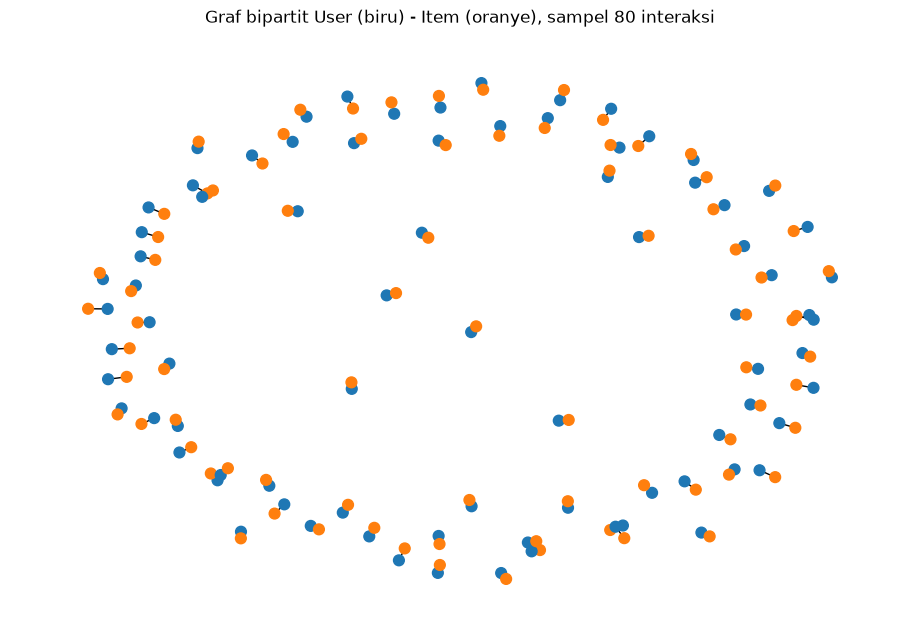

In [35]:
import networkx as nx
import matplotlib.pyplot as plt

sub = inter.sample(min(80, len(inter)), random_state=42)
G = nx.Graph()
for u, i in zip(sub["u"], sub["i"]):
    G.add_edge(f"U{u}", f"I{i}")
warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]

plt.figure(figsize=(9, 6))
nx.draw(G, node_color=warna, node_size=60, with_labels=False)
plt.title("Graf bipartit User (biru) - Item (oranye), sampel 80 interaksi")
plt.show()

- Nilai sel adalah bobot interaksi terkuat pasangan (user, item): VIEWED = 1, ADDED_TO_CART = 3, BOUGHT = 5. Bila ada beberapa interaksi, diambil bobot maksimum.
- Density = 219.852 / (147.816 × 76.702) ≈ 1,94 jadi sparsity ≈ 99,9981%. Matriks harus disimpan dalam format sparse (csr_matrix); bentuk dense tidak praktis.
- Distribusi derajat (tabel di atas) menunjukkan vektor User jauh lebih jarang terisi daripada vektor Item. Pada plot networkx, tiap user hanya terhubung ke sedikit item, sedangkan satu item dapat terhubung ke beberapa user. Plot memperlihatkan graf bipartit (User-Item) dari sampel kecil, bukan seluruh graf.

### Proyeksi mana yang lebih baik (efektif/efisien)

In [36]:
import time

t = time.time(); UU = (M @ M.T).tocsr(); t_uu = time.time() - t
t = time.time(); II = (M.T @ M).tocsr(); t_ii = time.time() - t

hasil = pd.DataFrame({
    "proyeksi": ["User-User", "Item-Item"],
    "simpul": [UU.shape[0], II.shape[0]],
    "nnz (edge)": [UU.nnz, II.nnz],
    "density": [UU.nnz / UU.shape[0]**2, II.nnz / II.shape[0]**2],
    "waktu (s)": [t_uu, t_ii],
    "memori (MB)": [(UU.data.nbytes + UU.indices.nbytes) / 1e6,
                    (II.data.nbytes + II.indices.nbytes) / 1e6],
})
display(hasil)

,proyeksi,simpul,nnz (edge),density,waktu (s),memori (MB)
0,User-User,147816,2553996,0.000117,0.032033,30.647952
1,Item-Item,76702,3606288,0.000613,0.067016,43.275456


Berdasarkan hasil perbandingan, proyeksi User-User lebih efisien dari sisi komputasi karena memiliki jumlah edge (2.553.996), waktu hitung (0,032 detik), dan penggunaan memori (30,65 MB) yang lebih kecil dibanding Item-Item (3.606.288 edge, 0,067 detik, 43,28 MB). Namun, proyeksi Item-Item memiliki jumlah simpul yang lebih sedikit (76.702) dan density yang lebih tinggi (0,000613), sehingga hubungan antar simpulnya lebih padat. Karena tugas pada bagian 2.2 adalah rekomendasi berbasis KNN antar user, proyeksi User-User dipilih sebagai dasar perhitungan similarity.

### Similarity pada graf terproyeksi

In [41]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=6, metric="cosine", algorithm="brute").fit(M)
dist, ind = nn.kneighbors(M)          # kolom 0 = dirinya sendiri

users = list(u_idx.keys())
rows = [
    {"a": int(users[a]), "b": int(users[b]), "s": float(1 - d)}
    for a in range(M.shape[0])
    for b, d in zip(ind[a][1:], dist[a][1:])
    if (1 - d) > 0
]

cy = """UNWIND $rows AS r
MATCH (a:Visitor {visitorId: r.a}), (b:Visitor {visitorId: r.b})
MERGE (a)-[x:SIMILAR]->(b) SET x.score = r.s"""

with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as d:
    with d.session(database="neo4j") as s:
        for k in range(0, len(rows), 5000):
            s.run(cy, rows=rows[k:k + 5000])
print("Relasi SIMILAR ditulis:", len(rows))

Relasi SIMILAR ditulis: 468648


(a) Cypher 5 record tertinggi

In [42]:
import random

users = list(u_idx.keys())
jumlah = np.diff(M.indptr)
kandidat = [k for k in range(M.shape[0]) if 5 <= jumlah[k] <= 50]
print("Kandidat:", len(kandidat))

rng = random.Random(42)
idx = rng.choice(kandidat)
acuan = int(users[idx])
print("Visitor acuan:", acuan, "| jumlah item:", jumlah[idx])

Kandidat: 3756
Visitor acuan: 984969 | jumlah item: 5


In [43]:
q = """MATCH (a:Visitor {visitorId: $id})-[s:SIMILAR]->(b:Visitor)
RETURN b.visitorId AS user_mirip, s.score AS similarity
ORDER BY similarity DESC LIMIT 5"""
with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as d:
    with d.session(database="neo4j") as s:
        display(pd.DataFrame(s.run(q, id=acuan).data()))

,user_mirip,similarity
0,539103,0.516398
1,1233103,0.447214
2,1283640,0.447214
3,1392219,0.447214
4,1218019,0.447214


Kondisi graf sebelum dan sesudah perhitungan similarity

Untuk visitor acuan 984969, kondisi graf dibandingkan lewat dua query Cypher.

- Sebelum similarity:

MATCH p=(v:Visitor {visitorId: 984969})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN p LIMIT 25

Visitor 984969 hanya terhubung ke simpul Item. Hasilnya 6 simpul (1 Visitor dan 5 Item) dengan 5 relasi VIEWED. Pada tahap ini belum ada relasi antar-visitor, jadi kemiripan antar pengguna belum bisa dilihat langsung di graf. Isi database saat itu 224.518 simpul dan 284.624 relasi, semuanya berasal dari event P1.

- Sesudah similarity

MATCH p=(v:Visitor {visitorId: 984969})-[:SIMILAR]->(b:Visitor)
RETURN p


Setelah similarity (cosine, KNN k=5) ditulis ke Neo4j, visitor 984969 punya 5 relasi SIMILAR ke visitor lain: 539103, 1233103, 1283640, 1392219, dan 1218019. Kelima simpul itu sama dengan hasil query top-5 pada no. 7(a), dan nilai kemiripannya tersimpan di properti score pada tiap relasi. Jumlah simpul tidak berubah (224.518). Yang bertambah hanya relasi, yaitu 468.648 relasi SIMILAR baru, sehingga totalnya menjadi 753.272.

Kesimpulan: sebelum similarity, hubungan antar-visitor hanya bisa ditelusuri lewat item yang sama-sama mereka lihat. Sesudahnya, hubungan itu sudah menjadi relasi langsung yang bisa di-query dan dipakai untuk rekomendasi KNN di bagian 2.2.

## 2.2 Analytics

In [45]:
import random
import numpy as np
import pandas as pd

# --- ground truth dari P2 ---
p2 = pd.read_csv("data/events_p2.csv")
p2_pos = p2[p2["event"].isin(["addtocart", "transaction"])]
truth = p2_pos.groupby("visitorid")["itemid"].apply(set).to_dict()

users_arr = np.array(list(u_idx.keys()))    # indeks baris M -> visitorId
items_arr = np.array(list(i_idx.keys()))    # indeks kolom M -> itemId
catalog = set(int(x) for x in items_arr)

def seen_items(u_row):
    return set(int(x) for x in items_arr[M[u_row].indices])

def relevant_items(u_row):
    vid = int(users_arr[u_row])
    return (set(int(x) for x in truth.get(vid, set())) & catalog) - seen_items(u_row)

jumlah = np.diff(M.indptr)
pool = [k for k in range(M.shape[0])
        if 5 <= jumlah[k] <= 50 and relevant_items(k)]
print("Kandidat user (punya >=1 item relevan di P2):", len(pool))

Kandidat user (punya >=1 item relevan di P2): 30


### 1. Memilih seorang user secara acak

a. Pemilihan user acak (reproducible) dan skrip KNN

In [46]:
SEED = 42
rng = random.Random(SEED)
target_row = rng.choice(pool)
target_id = int(users_arr[target_row])
print("User target:", target_id, "| item di P1:", jumlah[target_row])
print("Item relevan di P2:", sorted(relevant_items(target_row)))

User target: 1127595 | item di P1: 29
Item relevan di P2: [281942]


In [47]:
K = 5

def get_neighbors_neo4j(visitor_id, k=K):
    q = """MATCH (a:Visitor {visitorId: $id})-[s:SIMILAR]->(b:Visitor)
            WHERE a <> b
            RETURN b.visitorId AS b, s.score AS sim
            ORDER BY sim DESC, b ASC LIMIT $k"""
    with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as d:
        with d.session(database="neo4j") as s:
            return [(u_idx[r["b"]], r["sim"]) for r in s.run(q, id=visitor_id, k=k)]

def recommend(target_row, neighbors, topn=5):
    seen = set(M[target_row].indices)
    scores = {}
    for n_row, sim in neighbors:
        row = M[n_row]
        for j, w in zip(row.indices, row.data):
            if j in seen:
                continue
            scores[j] = scores.get(j, 0.0) + sim * w
    ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:topn]
    return [(int(items_arr[j]), float(sc)) for j, sc in ranked]

nbrs = get_neighbors_neo4j(target_id, K)
print("Tetangga KNN (k=5):")
display(pd.DataFrame({"visitorId": [int(users_arr[n]) for n, _ in nbrs],
                      "similarity": [s for _, s in nbrs]}))

Tetangga KNN (k=5):


,visitorId,similarity
0,1323752,0.763047
1,1209313,0.625954
2,97636,0.426562
3,1894,0.356466
4,361470,0.338179


b. Item yang diiklankan (k = 5)

In [48]:
rec5 = recommend(target_row, nbrs, topn=5)
rec_df = pd.DataFrame(rec5, columns=["itemId", "skor"])
rec_df["rank"] = range(1, len(rec_df) + 1)
rel = relevant_items(target_row)
rec_df["relevan_di_P2"] = rec_df["itemId"].isin(rel)
print("Daftar rekomendasi (top-5):")
display(rec_df)
print("3 item yang diiklankan:", [i for i, _ in rec5[:3]])

Daftar rekomendasi (top-5):


,itemId,skor,rank,relevan_di_P2
0,222163,3.655445,1,False
1,241950,2.234327,2,False
2,298214,1.877862,3,False
3,88975,1.727179,4,False
4,50019,0.763047,5,False


3 item yang diiklankan: [222163, 241950, 298214]


### 2. Menghitung Hit@5 dan NDCG@5

In [49]:
def hit_at_k(ranked_ids, relevant, k=5):
    return int(any(i in relevant for i in ranked_ids[:k]))

def ndcg_at_k(ranked_ids, relevant, k=5):
    dcg = sum(1 / np.log2(pos + 2) for pos, i in enumerate(ranked_ids[:k]) if i in relevant)
    ideal = sum(1 / np.log2(pos + 2) for pos in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

ranked_ids = [i for i, _ in rec5]
print("Item relevan (ground truth P2):", sorted(rel))
print("Top-5 rekomendasi            :", ranked_ids)
print("Hit@5  =", hit_at_k(ranked_ids, rel, 5))
print("NDCG@5 = %.4f" % ndcg_at_k(ranked_ids, rel, 5))
print("(tambahan) Hit@3 =", hit_at_k(ranked_ids, rel, 3), "| NDCG@3 = %.4f" % ndcg_at_k(ranked_ids, rel, 3))

Item relevan (ground truth P2): [281942]
Top-5 rekomendasi            : [222163, 241950, 298214, 88975, 50019]
Hit@5  = 0
NDCG@5 = 0.0000
(tambahan) Hit@3 = 0 | NDCG@3 = 0.0000
